In [71]:
# ============================================================
# 1. TITULO
# PROYECTO FINAL CURSO ML 2026 FIUNA
# Detección de humedales en el Chaco: 2005 vs 2025
# Random Forest + Google Earth Engine 
# ============================================================


In [72]:
# ============================================================
# 2. IMPORTAR LIBRERÍAS
# ============================================================

import os
import ee
import geemap
import geopandas as gpd
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Todas las librerías se importaron correctamente.")



Todas las librerías se importaron correctamente.


In [73]:
# ============================================================
# 3. RUTAS Y LECTURA DE SHAPEFILES
# ============================================================

import os
import geopandas as gpd

RUTA_PROYECTO = os.getcwd()

RUTA_SHAPES = os.path.join(
    RUTA_PROYECTO,
    "shapes")

RUTA_CHACO = os.path.join(
    RUTA_SHAPES,
    "Chaco.shp")

RUTA_PUNTOS_2005 = os.path.join(
    RUTA_SHAPES,
    "Sample_Points05.shp")

RUTA_PUNTOS_2025 = os.path.join(
    RUTA_SHAPES,
    "Sample_Points25.shp")

print("Verificando archivos...")

print("Chaco:", os.path.exists(RUTA_CHACO))
print("Puntos 2005:", os.path.exists(RUTA_PUNTOS_2005))
print("Puntos 2025:", os.path.exists(RUTA_PUNTOS_2025))

chaco = gpd.read_file(RUTA_CHACO)
points05 = gpd.read_file(RUTA_PUNTOS_2005)
points25 = gpd.read_file(RUTA_PUNTOS_2025)

print("\nCRS:")
print("Chaco:", chaco.crs)
print("Puntos 2005:", points05.crs)
print("Puntos 2025:", points25.crs)

print("\nCantidad de registros:")
print("Chaco:", len(chaco))
print("Puntos 2005:", len(points05))
print("Puntos 2025:", len(points25))

print("\nColumnas puntos 2005:")
print(points05.columns)

print("\nColumnas puntos 2025:")
print(points25.columns)

Verificando archivos...
Chaco: True
Puntos 2005: True
Puntos 2025: True

CRS:
Chaco: EPSG:4674
Puntos 2005: EPSG:32721
Puntos 2025: EPSG:32721

Cantidad de registros:
Chaco: 1
Puntos 2005: 1185
Puntos 2025: 1195

Columnas puntos 2005:
Index(['Id', 'ORIG_FID', 'geometry'], dtype='str')

Columnas puntos 2025:
Index(['Id', 'geometry'], dtype='str')


In [74]:
# ============================================================
# 4. CONEXIÓN A GOOGLE EARTH ENGINE
#    Y CONVERSIÓN DE VECTORES
# ============================================================

import ee
import geemap

# Inicializar Earth Engine con tu proyecto
ee.Initialize(project="ee-monserratgarciacalabrese")

print("Earth Engine conectado correctamente.")


# Reproyectar a WGS84
chaco_4326 = chaco.to_crs("EPSG:4326")
points05_4326 = points05.to_crs("EPSG:4326")
points25_4326 = points25.to_crs("EPSG:4326")

print("\nCRS reproyectados:")
print("Chaco:", chaco_4326.crs)
print("Puntos 2005:", points05_4326.crs)
print("Puntos 2025:", points25_4326.crs)


# Convertir GeoDataFrames a objetos de Earth Engine
ee_chaco = geemap.gdf_to_ee(chaco_4326)
ee_points05 = geemap.gdf_to_ee(points05_4326)
ee_points25 = geemap.gdf_to_ee(points25_4326)

region = ee_chaco.geometry()

print("\nVectores convertidos correctamente a Earth Engine.")

print("Puntos EE 2005:", ee_points05.size().getInfo())
print("Puntos EE 2025:", ee_points25.size().getInfo())

Earth Engine conectado correctamente.

CRS reproyectados:
Chaco: EPSG:4326
Puntos 2005: EPSG:4326
Puntos 2025: EPSG:4326

Vectores convertidos correctamente a Earth Engine.
Puntos EE 2005: 1185
Puntos EE 2025: 1195


In [ ]:
# ============================================================
# 5. PREPARAR LANDSAT 2005 Y 2025 - COMPOSICION DE IMAGENES SATELITALES
# ============================================================

# ------------------------------------------------------------
# Función Landsat 5 - año 2005
# ------------------------------------------------------------

def preparar_landsat5(image):

    qa = image.select("QA_PIXEL")

    mask = (
        qa.bitwiseAnd(1 << 1).eq(0)
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
    )

    bandas = (
        image.select([
            "SR_B1",
            "SR_B2",
            "SR_B3",
            "SR_B4",
            "SR_B5",
            "SR_B7"
        ])
        .multiply(0.0000275)
        .add(-0.2)
        .rename([
            "Blue",
            "Green",
            "Red",
            "NIR",
            "SWIR1",
            "SWIR2"
        ])
    )

    return bandas.updateMask(mask)


# ------------------------------------------------------------
# Función Landsat 8/9 - año 2025
# ------------------------------------------------------------

def preparar_landsat89(image):

    qa = image.select("QA_PIXEL")

    mask = (
        qa.bitwiseAnd(1 << 1).eq(0)
        .And(qa.bitwiseAnd(1 << 2).eq(0))
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
    )

    bandas = (
        image.select([
            "SR_B2",
            "SR_B3",
            "SR_B4",
            "SR_B5",
            "SR_B6",
            "SR_B7"
        ])
        .multiply(0.0000275)
        .add(-0.2)
        .rename([
            "Blue",
            "Green",
            "Red",
            "NIR",
            "SWIR1",
            "SWIR2"
        ])
    )

    return bandas.updateMask(mask)


# ------------------------------------------------------------
# Función índices espectrales
# ------------------------------------------------------------

def agregar_indices(image):

    ndvi = image.normalizedDifference(
        ["NIR", "Red"]
    ).rename("NDVI")

    ndwi = image.normalizedDifference(
        ["Green", "NIR"]
    ).rename("NDWI")

    mndwi = image.normalizedDifference(
        ["Green", "SWIR1"]
    ).rename("MNDWI")

    return image.addBands([
        ndvi,
        ndwi,
        mndwi
    ])


# ============================================================
# LANDSAT 2005
# ============================================================

collection05 = (
    ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
    .filterDate("2005-01-01", "2006-01-01")
    .filterBounds(region)
    .map(preparar_landsat5)
)

print(
    "Cantidad de imágenes 2005:",
    collection05.size().getInfo()
)

image05 = (
    collection05
    .median()
    .clip(region)
)

image05 = agregar_indices(image05)


# ============================================================
# LANDSAT 2025
# ============================================================

collection8 = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterDate("2025-01-01", "2026-01-01")
    .filterBounds(region)
    .map(preparar_landsat89)
)

collection9 = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterDate("2025-01-01", "2026-01-01")
    .filterBounds(region)
    .map(preparar_landsat89)
)

collection25 = collection8.merge(collection9)

print(
    "Cantidad de imágenes 2025:",
    collection25.size().getInfo()
)

image25 = (
    collection25
    .median()
    .clip(region)
)

image25 = agregar_indices(image25)


# ============================================================
# VERIFICAR BANDAS
# ============================================================

print("\nBandas imagen 2005:")
print(image05.bandNames().getInfo())

print("\nBandas imagen 2025:")
print(image25.bandNames().getInfo())

Cantidad de imágenes 2005: 350
Cantidad de imágenes 2025: 716

Bandas imagen 2005:
['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2', 'NDVI', 'NDWI', 'MNDWI']

Bandas imagen 2025:
['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2', 'NDVI', 'NDWI', 'MNDWI']


In [ ]:
# ============================================================
# 6. EXTRAER VALORES EN LOS PUNTOS DE ENTRENAMIENTO (MUESTRAS)
# ============================================================

FEATURES = [
    "Blue",
    "Green",
    "Red",
    "NIR",
    "SWIR1",
    "SWIR2",
    "NDVI",
    "NDWI",
    "MNDWI"
]

print("Extrayendo muestras 2005...")

sample05 = (
    image05
    .select(FEATURES)
    .sampleRegions(
        collection=ee_points05,
        properties=["Id"],
        scale=30,
        geometries=False,
        tileScale=4
    )
)

print(
    "Muestras válidas 2005:",
    sample05.size().getInfo()
)

print("\nExtrayendo muestras 2025...")

sample25 = (
    image25
    .select(FEATURES)
    .sampleRegions(
        collection=ee_points25,
        properties=["Id"],
        scale=30,
        geometries=False,
        tileScale=4
    )
)

print(
    "Muestras válidas 2025:",
    sample25.size().getInfo()
)


# ============================================================
# CONVERTIR FEATURECOLLECTION DE EARTH ENGINE A PANDAS
# ============================================================

print("\nConvirtiendo muestras a DataFrame...")


def ee_featurecollection_to_df(feature_collection):

    datos = feature_collection.getInfo()

    filas = []

    for feature in datos["features"]:
        filas.append(feature["properties"])

    return pd.DataFrame(filas)


# Convertir las muestras
df05 = ee_featurecollection_to_df(sample05)
df25 = ee_featurecollection_to_df(sample25)


# Agregar año
df05["year"] = 2005
df25["year"] = 2025


# Mostrar resultados
print("\nPrimeras filas 2005:")
print(df05.head())

print("\nPrimeras filas 2025:")
print(df25.head())

print("\nDimensiones:")
print("2005:", df05.shape)
print("2025:", df25.shape)

print("\nColumnas 2005:")
print(df05.columns.tolist())

print("\nColumnas 2025:")
print(df25.columns.tolist())

Extrayendo muestras 2005...
Muestras válidas 2005: 1185

Extrayendo muestras 2025...
Muestras válidas 2025: 1195

Convirtiendo muestras a DataFrame...

Primeras filas 2005:
       Blue     Green  Id     MNDWI      NDVI      NDWI       NIR       Red  \
0  0.024318  0.042357   1 -0.540392  0.730901 -0.688552  0.229646  0.035702   
1  0.026545  0.046964   1 -0.499630  0.708734 -0.639027  0.213243  0.036349   
2  0.021787  0.040405   1 -0.534196  0.750039 -0.675677  0.208760  0.029817   
3  0.024139  0.045630   1 -0.499129  0.717085 -0.649538  0.214769  0.035386   
4  0.025803  0.045465   1 -0.504529  0.738042 -0.675957  0.235146  0.035441   

      SWIR1     SWIR2  year  
0  0.141962  0.060796  2005  
1  0.140753  0.056382  2005  
2  0.133080  0.052835  2005  
3  0.136573  0.057042  2005  
4  0.138057  0.056603  2005  

Primeras filas 2025:
       Blue     Green  Id     MNDWI      NDVI      NDWI       NIR       Red  \
0  0.021815  0.046923   1 -0.524155  0.789015 -0.676614  0.243273  0.02

In [75]:
# ============================================================
# 7. PREPARAR DATASETS POR AÑO Y CREAR datos_muestra.csv
# ============================================================

COLUMNAS_MODELO = ["Id", "year", "Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2", "NDVI", "NDWI", "MNDWI"]

# ============================================================
# PREPARAR DATASET 2005
# ============================================================

df05 = df05[COLUMNAS_MODELO].copy()

df05["Id"] = pd.to_numeric(df05["Id"], errors="coerce")

for col in FEATURES:
    df05[col] = pd.to_numeric(df05[col], errors="coerce")

df05 = df05.dropna(subset=["Id"] + FEATURES).copy()
df05["Id"] = df05["Id"].astype(int)
df05["year"] = 2005

print("==========================================")
print("DATASET 2005")
print("==========================================")
print("Dimensiones:", df05.shape)
print("\nMuestras por clase:")
print(df05["Id"].value_counts().sort_index())
print("\nValores faltantes:")
print(df05.isna().sum())

# ============================================================
# PREPARAR DATASET 2025
# ============================================================

df25 = df25[COLUMNAS_MODELO].copy()

df25["Id"] = pd.to_numeric(df25["Id"], errors="coerce")

for col in FEATURES:
    df25[col] = pd.to_numeric(df25[col], errors="coerce")

df25 = df25.dropna(subset=["Id"] + FEATURES).copy()
df25["Id"] = df25["Id"].astype(int)
df25["year"] = 2025

print("\n==========================================")
print("DATASET 2025")
print("==========================================")
print("Dimensiones:", df25.shape)
print("\nMuestras por clase:")
print(df25["Id"].value_counts().sort_index())
print("\nValores faltantes:")
print(df25.isna().sum())

# ============================================================
# NOMBRES DE CLASES
# ============================================================

NOMBRES_CLASES = {
    1: "Bosque hidromórfico",
    2: "Bosque xerofítico",
    3: "Cuerpos de agua",
    4: "Tierras manejadas",
    5: "Sabanas con árboles y arbustales",
    6: "Sabanas hidromórficas",
    7: "Humedales"
}

df05["clase_nombre"] = df05["Id"].map(NOMBRES_CLASES)
df25["clase_nombre"] = df25["Id"].map(NOMBRES_CLASES)

# ============================================================
# GUARDAR DATASETS COMPLETOS POR AÑO
# NO SE ENTREGAN, SOLO PARA TRABAJO LOCAL
# ============================================================

RUTA_DATASET_2005 = os.path.join(RUTA_PROYECTO, "datos_entrenamiento_2005.csv")
RUTA_DATASET_2025 = os.path.join(RUTA_PROYECTO, "datos_entrenamiento_2025.csv")

df05.to_csv(RUTA_DATASET_2005, index=False)
df25.to_csv(RUTA_DATASET_2025, index=False)

print("\n==========================================")
print("DATASETS COMPLETOS GUARDADOS")
print("==========================================")
print(RUTA_DATASET_2005)
print(RUTA_DATASET_2025)

# ============================================================
# CREAR datos_muestra.csv
# SOLO PARA LA ENTREGA DEL PROYECTO
# ============================================================

muestra05 = df05.sample(n=50, random_state=42)
muestra25 = df25.sample(n=50, random_state=42)

datos_muestra = pd.concat([muestra05, muestra25], ignore_index=True)

RUTA_DATOS_MUESTRA = os.path.join(RUTA_PROYECTO, "datos_muestra.csv")
datos_muestra.to_csv(RUTA_DATOS_MUESTRA, index=False)

print("\n==========================================")
print("datos_muestra.csv CREADO")
print("==========================================")
print("Filas 2005:", len(muestra05))
print("Filas 2025:", len(muestra25))
print("Total:", len(datos_muestra))
print("Ruta:", RUTA_DATOS_MUESTRA)

DATASET 2005
Dimensiones: (1185, 11)

Muestras por clase:
Id
1    107
2    371
3     58
4    339
5     62
6    184
7     64
Name: count, dtype: int64

Valores faltantes:
Id       0
year     0
Blue     0
Green    0
Red      0
NIR      0
SWIR1    0
SWIR2    0
NDVI     0
NDWI     0
MNDWI    0
dtype: int64

DATASET 2025
Dimensiones: (1195, 11)

Muestras por clase:
Id
1    107
2    362
3     58
4    364
5     56
6    184
7     64
Name: count, dtype: int64

Valores faltantes:
Id       0
year     0
Blue     0
Green    0
Red      0
NIR      0
SWIR1    0
SWIR2    0
NDVI     0
NDWI     0
MNDWI    0
dtype: int64

DATASETS COMPLETOS GUARDADOS
/Users/monserratgarciacalabrese/Diplomado/TP_FINAL/datos_entrenamiento_2005.csv
/Users/monserratgarciacalabrese/Diplomado/TP_FINAL/datos_entrenamiento_2025.csv

datos_muestra.csv CREADO
Filas 2005: 50
Filas 2025: 50
Total: 100
Ruta: /Users/monserratgarciacalabrese/Diplomado/TP_FINAL/datos_muestra.csv



AÑO 2005
Total muestras: 1185
Train: 829
Test: 356

Entrenando Logistic Regression...
Entrenando Random Forest...

COMPARACIÓN DE MODELOS
    Año               Modelo  Accuracy_global   Kappa  F1_macro_global  \
0  2005  Logistic Regression           0.5393  0.4424           0.5055   
1  2005        Random Forest           0.6713  0.5859           0.6392   

   Precision_humedal  Recall_humedal  F1_humedal  
0             0.3171          0.6842      0.4333  
1             0.5882          0.5263      0.5556  

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           1     0.3529    0.7500    0.4800        32
           2     0.8028    0.5089    0.6230       112
           3     1.0000    0.4706    0.6400        17
           4     0.8429    0.5784    0.6860       102
           5     0.1860    0.4211    0.2581        19
           6     0.4182    0.4182    0.4182        55
           7     0.3171    0.6842    0.4333        19

    accuracy                  

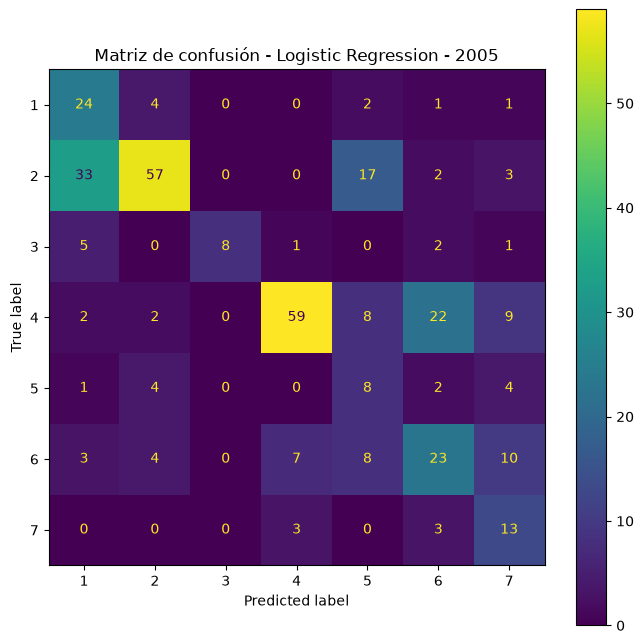

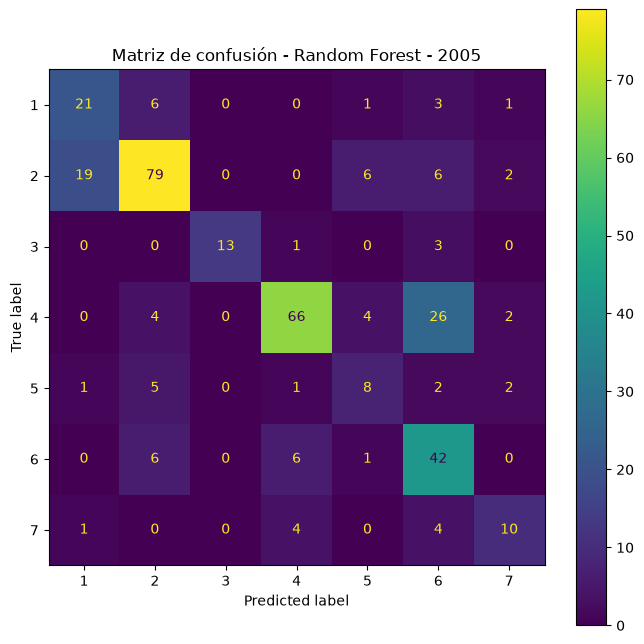


MODELO SELECCIONADO 2005 : Random Forest

AÑO 2025
Total muestras: 1195
Train: 836
Test: 359

Entrenando Logistic Regression...
Entrenando Random Forest...

COMPARACIÓN DE MODELOS
    Año               Modelo  Accuracy_global   Kappa  F1_macro_global  \
0  2025  Logistic Regression           0.6797  0.5993           0.6174   
1  2025        Random Forest           0.7270  0.6487           0.6536   

   Precision_humedal  Recall_humedal  F1_humedal  
0             0.4000          0.5263      0.4545  
1             0.3889          0.3684      0.3784  

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           1     0.4727    0.8125    0.5977        32
           2     0.8172    0.6972    0.7525       109
           3     0.8947    0.9444    0.9189        18
           4     0.9247    0.7890    0.8515       109
           5     0.2500    0.4118    0.3111        17
           6     0.4783    0.4000    0.4356        55
           7     0.4000    0.5263    0.4545

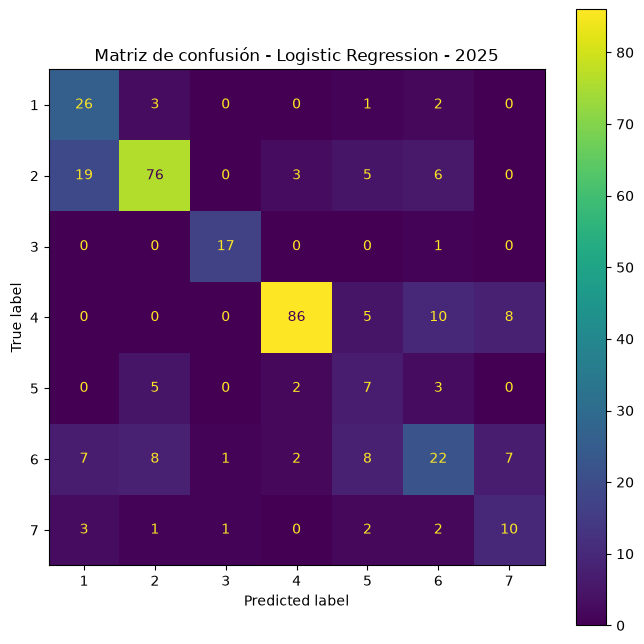

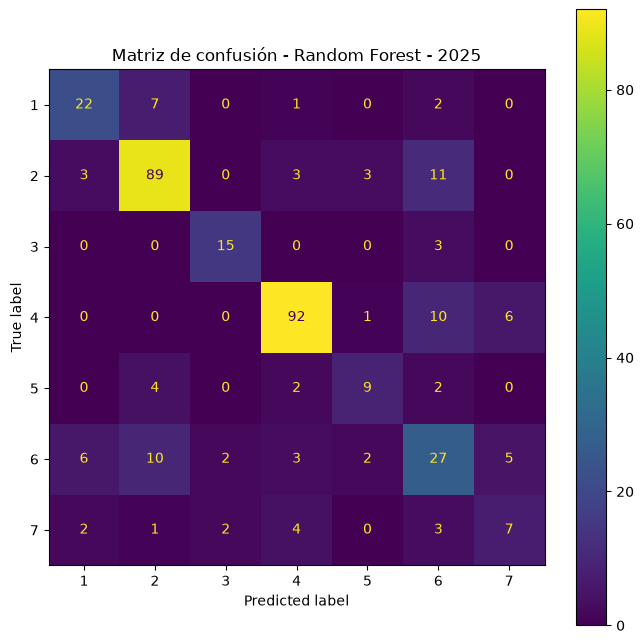


MODELO SELECCIONADO 2025 : Logistic Regression

RESUMEN FINAL DE MODELOS
    Año               Modelo  Accuracy_global   Kappa  F1_macro_global  \
0  2005  Logistic Regression           0.5393  0.4424           0.5055   
1  2005        Random Forest           0.6713  0.5859           0.6392   
2  2025  Logistic Regression           0.6797  0.5993           0.6174   
3  2025        Random Forest           0.7270  0.6487           0.6536   

   Precision_humedal  Recall_humedal  F1_humedal  
0             0.3171          0.6842      0.4333  
1             0.5882          0.5263      0.5556  
2             0.4000          0.5263      0.4545  
3             0.3889          0.3684      0.3784  


In [76]:
# ============================================================
# 8. COMPARAR DOS MODELOS POR AÑO
# 2005 y 2025 se entrenan y evalúan por separado
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score
import pandas as pd
import matplotlib.pyplot as plt

FEATURES = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2", "NDVI", "NDWI", "MNDWI"]
CLASE_HUMEDAL = 7

# ============================================================
# FUNCIÓN PARA ENTRENAR Y EVALUAR CADA AÑO
# ============================================================

def evaluar_modelos_por_anio(df_anio, anio):

    X = df_anio[FEATURES].copy()
    y = df_anio["Id"].copy()

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

    print("\n==========================================")
    print(f"AÑO {anio}")
    print("==========================================")
    print("Total muestras:", len(X))
    print("Train:", len(X_train))
    print("Test:", len(X_test))

    # ========================================================
    # MODELO 1 - LOGISTIC REGRESSION
    # ========================================================

    preprocessor_lr = ColumnTransformer([("numericas", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), FEATURES)])
    modelo_lr = Pipeline([("preprocessor", preprocessor_lr), ("classifier", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))])

    print("\nEntrenando Logistic Regression...")
    modelo_lr.fit(X_train, y_train)
    pred_lr = modelo_lr.predict(X_test)

    # ========================================================
    # MODELO 2 - RANDOM FOREST
    # ========================================================

    preprocessor_rf = ColumnTransformer([("numericas", Pipeline([("imputer", SimpleImputer(strategy="median"))]), FEATURES)])
    modelo_rf = Pipeline([("preprocessor", preprocessor_rf), ("classifier", RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=42, n_jobs=-1))])

    print("Entrenando Random Forest...")
    modelo_rf.fit(X_train, y_train)
    pred_rf = modelo_rf.predict(X_test)

    # ========================================================
    # MÉTRICAS GLOBALES
    # ========================================================

    accuracy_lr = accuracy_score(y_test, pred_lr)
    f1_macro_lr = f1_score(y_test, pred_lr, average="macro")
    kappa_lr = cohen_kappa_score(y_test, pred_lr)

    accuracy_rf = accuracy_score(y_test, pred_rf)
    f1_macro_rf = f1_score(y_test, pred_rf, average="macro")
    kappa_rf = cohen_kappa_score(y_test, pred_rf)

    # ========================================================
    # MÉTRICAS ESPECÍFICAS DE HUMEDALES
    # ========================================================

    precision_lr, recall_lr, f1_humedal_lr, soporte_lr = precision_recall_fscore_support(y_test, pred_lr, labels=[CLASE_HUMEDAL], average=None, zero_division=0)
    precision_rf, recall_rf, f1_humedal_rf, soporte_rf = precision_recall_fscore_support(y_test, pred_rf, labels=[CLASE_HUMEDAL], average=None, zero_division=0)

    precision_lr, recall_lr, f1_humedal_lr, soporte_lr = precision_lr[0], recall_lr[0], f1_humedal_lr[0], soporte_lr[0]
    precision_rf, recall_rf, f1_humedal_rf, soporte_rf = precision_rf[0], recall_rf[0], f1_humedal_rf[0], soporte_rf[0]

    # ========================================================
    # TABLA DE RESULTADOS
    # ========================================================

    resultados = pd.DataFrame({
        "Año": [anio, anio],
        "Modelo": ["Logistic Regression", "Random Forest"],
        "Accuracy_global": [accuracy_lr, accuracy_rf],
        "Kappa": [kappa_lr, kappa_rf],
        "F1_macro_global": [f1_macro_lr, f1_macro_rf],
        "Precision_humedal": [precision_lr, precision_rf],
        "Recall_humedal": [recall_lr, recall_rf],
        "F1_humedal": [f1_humedal_lr, f1_humedal_rf]
    })

    print("\nCOMPARACIÓN DE MODELOS")
    print(resultados.round(4))

    # ========================================================
    # REPORTE COMPLETO - LOGISTIC REGRESSION
    # ========================================================

    print("\nLOGISTIC REGRESSION")
    print(classification_report(y_test, pred_lr, digits=4))

    # ========================================================
    # REPORTE COMPLETO - RANDOM FOREST
    # ========================================================

    print("\nRANDOM FOREST")
    print(classification_report(y_test, pred_rf, digits=4))

    # ========================================================
    # MATRIZ DE CONFUSIÓN - LOGISTIC REGRESSION
    # ========================================================

    cm_lr = confusion_matrix(y_test, pred_lr)
    disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=sorted(y.unique()))
    fig, ax = plt.subplots(figsize=(8, 8))
    disp_lr.plot(ax=ax, values_format="d")
    plt.title(f"Matriz de confusión - Logistic Regression - {anio}")
    plt.show()

    # ========================================================
    # MATRIZ DE CONFUSIÓN - RANDOM FOREST
    # ========================================================

    cm_rf = confusion_matrix(y_test, pred_rf)
    disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=sorted(y.unique()))
    fig, ax = plt.subplots(figsize=(8, 8))
    disp_rf.plot(ax=ax, values_format="d")
    plt.title(f"Matriz de confusión - Random Forest - {anio}")
    plt.show()

    # ========================================================
    # SELECCIÓN DEL MEJOR MODELO
    # Prioridad: F1 Humedal; empate -> Recall Humedal
    # ========================================================

    if f1_humedal_rf > f1_humedal_lr:
        mejor_modelo = modelo_rf
        mejor_nombre = "Random Forest"
    elif f1_humedal_lr > f1_humedal_rf:
        mejor_modelo = modelo_lr
        mejor_nombre = "Logistic Regression"
    else:
        mejor_modelo = modelo_rf if recall_rf >= recall_lr else modelo_lr
        mejor_nombre = "Random Forest" if recall_rf >= recall_lr else "Logistic Regression"

    print("\nMODELO SELECCIONADO", anio, ":", mejor_nombre)

    return {
        "anio": anio,
        "X": X,
        "y": y,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "modelo_lr": modelo_lr,
        "modelo_rf": modelo_rf,
        "pred_lr": pred_lr,
        "pred_rf": pred_rf,
        "resultados": resultados,
        "mejor_modelo": mejor_modelo,
        "mejor_nombre": mejor_nombre
    }

# ============================================================
# EVALUAR 2005
# ============================================================

resultado_2005 = evaluar_modelos_por_anio(df05, 2005)

# ============================================================
# EVALUAR 2025
# ============================================================

resultado_2025 = evaluar_modelos_por_anio(df25, 2025)

# ============================================================
# RESUMEN FINAL DE LOS CUATRO MODELOS
# ============================================================

tabla_final_modelos = pd.concat([resultado_2005["resultados"], resultado_2025["resultados"]], ignore_index=True)

print("\n==========================================")
print("RESUMEN FINAL DE MODELOS")
print("==========================================")
print(tabla_final_modelos.round(4))

In [77]:
# ============================================================
# 9. GUARDAR LOS MODELOS FINALES EN model.pkl
# ============================================================

import joblib
import os

# ============================================================
# REENTRENAR RANDOM FOREST 2005 CON TODAS LAS MUESTRAS 2005
# ============================================================

X_2005_final = df05[FEATURES].copy()
y_2005_final = df05["Id"].copy()

modelo_rf_2005_final = resultado_2005["modelo_rf"]
modelo_rf_2005_final.fit(X_2005_final, y_2005_final)

print("Modelo 2005 reentrenado con:", len(X_2005_final), "muestras")

# ============================================================
# REENTRENAR RANDOM FOREST 2025 CON TODAS LAS MUESTRAS 2025
# ============================================================

X_2025_final = df25[FEATURES].copy()
y_2025_final = df25["Id"].copy()

modelo_rf_2025_final = resultado_2025["modelo_rf"]
modelo_rf_2025_final.fit(X_2025_final, y_2025_final)

print("Modelo 2025 reentrenado con:", len(X_2025_final), "muestras")

# ============================================================
# GUARDAR LOS DOS MODELOS EN UN SOLO ARCHIVO model.pkl
# ============================================================

RUTA_MODELO = os.path.join(RUTA_PROYECTO, "model.pkl")

modelos_finales = {
    "2005": modelo_rf_2005_final,
    "2025": modelo_rf_2025_final
}

joblib.dump(modelos_finales, RUTA_MODELO)

print("\nModelo guardado en:", RUTA_MODELO)

# ============================================================
# PRUEBA DE joblib.load()
# ============================================================

modelos_cargados = joblib.load(RUTA_MODELO)

modelo_2005_cargado = modelos_cargados["2005"]
modelo_2025_cargado = modelos_cargados["2025"]

prediccion_2005 = modelo_2005_cargado.predict(X_2005_final.iloc[[0]])[0]
prediccion_2025 = modelo_2025_cargado.predict(X_2025_final.iloc[[0]])[0]

print("\n==========================================")
print("PRUEBA DE model.pkl")
print("==========================================")
print("Predicción 2005:", prediccion_2005)
print("Clase real 2005:", y_2005_final.iloc[0])
print("Predicción 2025:", prediccion_2025)
print("Clase real 2025:", y_2025_final.iloc[0])
print("\nmodel.pkl cargado correctamente con joblib.load()")

Modelo 2005 reentrenado con: 1185 muestras
Modelo 2025 reentrenado con: 1195 muestras

Modelo guardado en: /Users/monserratgarciacalabrese/Diplomado/TP_FINAL/model.pkl

PRUEBA DE model.pkl
Predicción 2005: 1
Clase real 2005: 1
Predicción 2025: 1
Clase real 2025: 1

model.pkl cargado correctamente con joblib.load()


In [27]:
# ============================================================
# 10. CLASIFICACIÓN ESPACIAL Y CAMBIO DE HUMEDALES
# Random Forest independiente para 2005 y 2025
# ============================================================

# ============================================================
# RANDOM FOREST 2005 - TODAS LAS MUESTRAS 2005
# ============================================================

clasificador_ee_2005 = ee.Classifier.smileRandomForest(numberOfTrees=500, seed=42).train(features=sample05, classProperty="Id", inputProperties=FEATURES)

clasificacion05 = image05.select(FEATURES).classify(clasificador_ee_2005).rename("clasificacion_2005")

print("Clasificación 2005 preparada.")

# ============================================================
# RANDOM FOREST 2025 - TODAS LAS MUESTRAS 2025
# ============================================================

clasificador_ee_2025 = ee.Classifier.smileRandomForest(numberOfTrees=500, seed=42).train(features=sample25, classProperty="Id", inputProperties=FEATURES)

clasificacion25 = image25.select(FEATURES).classify(clasificador_ee_2025).rename("clasificacion_2025")

print("Clasificación 2025 preparada.")

# ============================================================
# EXTRAER HUMEDALES - CLASE 7
# ============================================================

humedal05 = clasificacion05.eq(7).rename("humedal_2005")
humedal25 = clasificacion25.eq(7).rename("humedal_2025")

# ============================================================
# CAMBIO DE HUMEDALES 2005 - 2025
# ============================================================

persistencia = humedal05.And(humedal25).rename("Persistencia")
perdida = humedal05.And(humedal25.Not()).rename("Perdida")
ganancia = humedal05.Not().And(humedal25).rename("Ganancia")

# ============================================================
# SUPERFICIES EN HECTÁREAS
# ============================================================

pixel_ha = ee.Image.pixelArea().divide(10000)

areas = ee.Image.cat([
    pixel_ha.updateMask(humedal05).rename("Humedal_2005"),
    pixel_ha.updateMask(humedal25).rename("Humedal_2025"),
    pixel_ha.updateMask(persistencia).rename("Persistencia"),
    pixel_ha.updateMask(perdida).rename("Perdida"),
    pixel_ha.updateMask(ganancia).rename("Ganancia")
])

resultado_areas = areas.reduceRegion(reducer=ee.Reducer.sum(), geometry=region, scale=30, maxPixels=1e13, tileScale=16)

# ============================================================
# PREPARAR EXPORTACIÓN BATCH
# ============================================================

resultado_feature = ee.Feature(None, resultado_areas)
resultado_fc = ee.FeatureCollection([resultado_feature])

# ============================================================
# EXPORTAR RESULTADOS A GOOGLE DRIVE
# ============================================================

task = ee.batch.Export.table.toDrive(collection=resultado_fc, description="areas_humedales_RF_2005_2025", folder="EarthEngine", fileNamePrefix="areas_humedales_RF_2005_2025", fileFormat="CSV")

task.start()

print("\n==========================================")
print("EXPORTACIÓN INICIADA")
print("==========================================")
print("Estado:", task.status()["state"])
print("ID:", task.id)
print("Archivo esperado:")
print("EarthEngine/areas_humedales_RF_2005_2025.csv")

# ============================================================
# MAPA DE RESULTADOS
# ============================================================

Map = geemap.Map()
Map.centerObject(ee_chaco, 6)
Map.addLayer(humedal05.selfMask(), {"palette": ["blue"]}, "Humedales 2005")
Map.addLayer(humedal25.selfMask(), {"palette": ["cyan"]}, "Humedales 2025")
Map.addLayer(perdida.selfMask(), {"palette": ["red"]}, "Pérdida 2005-2025")
Map.addLayer(ganancia.selfMask(), {"palette": ["green"]}, "Ganancia 2005-2025")

Map

Clasificación 2005 preparada.
Clasificación 2025 preparada.


/usr/local/Caskroom/miniforge/base/envs/tp_final/lib/python3.11/site-packages/ee/data.py:335: UserWarning: Your project has exceeded its noncommercial compute quota and is now in restricted mode. Visit https://developers.google.com/earth-engine/guides/noncommercial_tiers#restricted_mode to learn more.
  warnings.warn(



EXPORTACIÓN INICIADA
Estado: READY
ID: OZJPTXYVZF3F5RYRC7Q6KT64
Archivo esperado:
EarthEngine/areas_humedales_RF_2005_2025.csv


Map(center=[-21.998785705000405, -59.795952976729836], controls=(WidgetControl(options=['position', 'transpare…

In [37]:
# ============================================================
# 11. VER ESTADO DE LA EXPORTACIÓN
# ============================================================

estado = task.status()

print("Estado:", estado["state"])

if estado["state"] == "COMPLETED":
    print("Exportación terminada correctamente.")
elif estado["state"] == "FAILED":
    print("La tarea falló.")
    print("Error:", estado.get("error_message", "Sin detalle"))
else:
    print("La tarea todavía está procesándose.")

Estado: COMPLETED
Exportación terminada correctamente.


Archivo cargado correctamente.
   system:index       Ganancia   Humedal_2005   Humedal_2025        Perdida  \
0             0  334038.674749  359087.110136  362217.765354  330908.019531   

   Persistencia                                    .geo  
0  28179.090605  {"type":"MultiPoint","coordinates":[]}  

CAMBIO DE HUMEDALES 2005 - 2025
     Indicador  Superficie_ha
Humedales 2005      359087.11
Humedales 2025      362217.77
  Persistencia       28179.09
       Pérdida      330908.02
      Ganancia      334038.67
   Cambio neto        3130.66

INDICADORES PORCENTUALES
Persistencia: 7.85%
Pérdida: 92.15%
Ganancia: 93.02%
Cambio neto: 3,130.66 ha
Cambio neto porcentual: 0.87%


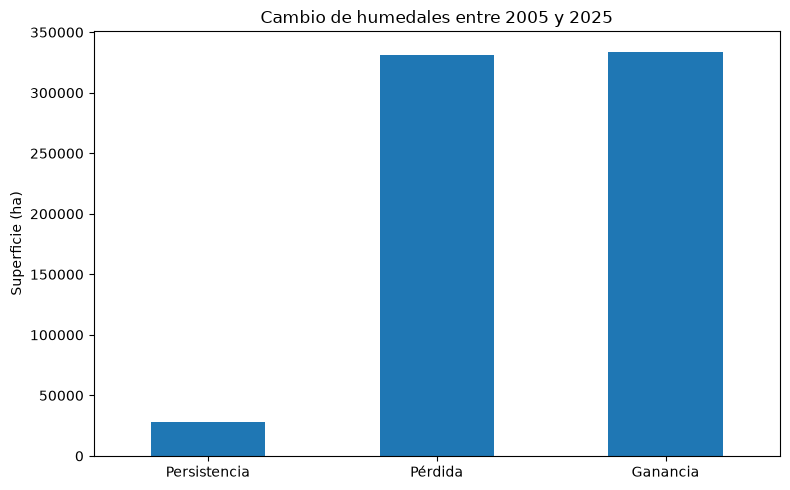

In [78]:
# ============================================================
# 12. RESULTADOS FINALES DEL CAMBIO DE HUMEDALES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import os

# ============================================================
# LEER CSV EXPORTADO DESDE EARTH ENGINE
# ============================================================

RUTA_RESULTADOS = os.path.join(
    RUTA_PROYECTO,
    "areas_humedales_RF_2005_2025.csv"
)

resultados_ee = pd.read_csv(RUTA_RESULTADOS)

print("Archivo cargado correctamente.")
print(resultados_ee)

# ============================================================
# EXTRAER SUPERFICIES
# ============================================================

area_2005 = resultados_ee.loc[0, "Humedal_2005"]
area_2025 = resultados_ee.loc[0, "Humedal_2025"]

persistencia_ha = resultados_ee.loc[0, "Persistencia"]
perdida_ha = resultados_ee.loc[0, "Perdida"]
ganancia_ha = resultados_ee.loc[0, "Ganancia"]

# ============================================================
# CALCULAR INDICADORES
# ============================================================

persistencia_pct = (persistencia_ha / area_2005) * 100
perdida_pct = (perdida_ha / area_2005) * 100
ganancia_pct = (ganancia_ha / area_2005) * 100

cambio_neto = area_2025 - area_2005
cambio_neto_pct = (cambio_neto / area_2005) * 100

# ============================================================
# TABLA FINAL
# ============================================================

tabla_cambio = pd.DataFrame({
    "Indicador": [
        "Humedales 2005",
        "Humedales 2025",
        "Persistencia",
        "Pérdida",
        "Ganancia",
        "Cambio neto"
    ],
    "Superficie_ha": [
        area_2005,
        area_2025,
        persistencia_ha,
        perdida_ha,
        ganancia_ha,
        cambio_neto
    ]
})

print("\n==========================================")
print("CAMBIO DE HUMEDALES 2005 - 2025")
print("==========================================")
print(tabla_cambio.round(2).to_string(index=False))

print("\n==========================================")
print("INDICADORES PORCENTUALES")
print("==========================================")
print(f"Persistencia: {persistencia_pct:.2f}%")
print(f"Pérdida: {perdida_pct:.2f}%")
print(f"Ganancia: {ganancia_pct:.2f}%")
print(f"Cambio neto: {cambio_neto:,.2f} ha")
print(f"Cambio neto porcentual: {cambio_neto_pct:.2f}%")

# ============================================================
# GRÁFICO FINAL
# ============================================================

grafico = pd.DataFrame({
    "Categoría": [
        "Persistencia",
        "Pérdida",
        "Ganancia"
    ],
    "Superficie_ha": [
        persistencia_ha,
        perdida_ha,
        ganancia_ha
    ]
})

grafico.plot(
    x="Categoría",
    y="Superficie_ha",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Cambio de humedales entre 2005 y 2025")
plt.ylabel("Superficie (ha)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 13. EXPORTAR RASTERS DE HUMEDALES A EARTH ENGINE ASSETS
# ============================================================

ASSET_2005 = (
    "projects/ee-monserratgarciacalabrese/"
    "assets/humedales_2005_RF"
)

ASSET_2025 = (
    "projects/ee-monserratgarciacalabrese/"
    "assets/humedales_2025_RF"
)

# ============================================================
# PREPARAR RASTERS
# ============================================================

humedal05_final = (
    clasificacion05
    .eq(7)
    .toByte()
    .rename("Humedal_2005")
    .clip(region)
)

humedal25_final = (
    clasificacion25
    .eq(7)
    .toByte()
    .rename("Humedal_2025")
    .clip(region)
)

# ============================================================
# FUNCIÓN PARA VERIFICAR SI EL ASSET YA EXISTE
# ============================================================

def asset_existe(asset_id):
    try:
        ee.data.getAsset(asset_id)
        return True
    except Exception:
        return False

# ============================================================
# EXPORTAR 2005
# ============================================================

if not asset_existe(ASSET_2005):

    task05 = ee.batch.Export.image.toAsset(
        image=humedal05_final,
        description="humedales_2005_RF",
        assetId=ASSET_2005,
        region=region,
        scale=30,
        maxPixels=1e13
    )

    task05.start()

    print("Exportación 2005 lanzada.")

else:
    print("Asset 2005 ya existe.")

# ============================================================
# EXPORTAR 2025
# ============================================================

if not asset_existe(ASSET_2025):

    task25 = ee.batch.Export.image.toAsset(
        image=humedal25_final,
        description="humedales_2025_RF",
        assetId=ASSET_2025,
        region=region,
        scale=30,
        maxPixels=1e13
    )

    task25.start()

    print("Exportación 2025 lanzada.")

else:
    print("Asset 2025 ya existe.")

2025 lanzado.


In [79]:
# ============================================================
# 14 CONSULTAR ESTADO DE LANZAMIENTO 2005 Y 2025
# ============================================================

for task in ee.batch.Task.list():
    estado = task.status()
    descripcion = estado.get("description", "")

    if "humedales_2005_RF" in descripcion or "humedales_2025_RF" in descripcion:
        print(
            descripcion,
            "->",
            estado.get("state"),
            estado.get("error_message", "")
        )

humedales_2025_RF -> COMPLETED 
humedales_2005_RF -> COMPLETED 


In [80]:
# ============================================================
# 15 VISOR FINAL DE LOS RESULTADOS EN MAPAS DESDE ASSETS YA PROCESADOS
# ============================================================

ASSET_2005 = "projects/ee-monserratgarciacalabrese/assets/humedales_2005_RF"
ASSET_2025 = "projects/ee-monserratgarciacalabrese/assets/humedales_2025_RF"

humedal05_asset = ee.Image(ASSET_2005)
humedal25_asset = ee.Image(ASSET_2025)

# ============================================================
# CAMBIOS
# ============================================================

persistencia_asset = (
    humedal05_asset.eq(1)
    .And(humedal25_asset.eq(1))
    .selfMask()
)

perdida_asset = (
    humedal05_asset.eq(1)
    .And(humedal25_asset.eq(0))
    .selfMask()
)

ganancia_asset = (
    humedal05_asset.eq(0)
    .And(humedal25_asset.eq(1))
    .selfMask()
)

# ============================================================
# MAPA
# ============================================================

Map = geemap.Map()
Map.add_basemap("SATELLITE")

xmin, ymin, xmax, ymax = chaco_4326.total_bounds
Map.fit_bounds([[ymin, xmin], [ymax, xmax]])

Map.addLayer(
    humedal05_asset.selfMask(),
    {"palette": ["0000FF"]},
    "Humedales 2005",
    True
)

Map.addLayer(
    humedal25_asset.selfMask(),
    {"palette": ["00FFFF"]},
    "Humedales 2025",
    False
)

Map.addLayer(
    persistencia_asset,
    {"palette": ["00AA00"]},
    "Persistencia",
    False
)

Map.addLayer(
    perdida_asset,
    {"palette": ["FF0000"]},
    "Pérdida",
    False
)

Map.addLayer(
    ganancia_asset,
    {"palette": ["FF00FF"]},
    "Ganancia",
    False
)

Map.add_geojson(
    chaco_4326.__geo_interface__,
    layer_name="Límite del Chaco",
    style={
        "color": "#FF0000",
        "weight": 3,
        "fillOpacity": 0
    }
)

Map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…